In [1]:

import sys
import torch
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("CartPole actions:", gym.make("CartPole-v1").action_space.n)
print("MsPacman actions:", gym.make("ALE/MsPacman-v5").action_space.n)

x = torch.tensor([1.0, 2.0], device="cuda")
print("GPU calculation:", x * 2)



Python: /nfs/home/zyd9530/RL_Assignment2/rl_env/bin/python
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti
CartPole actions: 2
MsPacman actions: 9


A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


GPU calculation: tensor([2., 4.], device='cuda:0')


In [2]:

import random
from collections import deque, namedtuple

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)


env = gym.make("CartPole-v1")
env.action_space.seed(SEED)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n


GAMMA = 0.95
LEARNING_RATE = 1e-3
BATCH_SIZE = 64
BUFFER_SIZE = 50000
TARGET_UPDATE = 10

EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.995

NUM_EPISODES = 1000

print("Device:", device)
print("State dimension:", state_dim)
print("Action dimension:", action_dim)
print("Discount factor:", GAMMA)
print("Number of episodes:", NUM_EPISODES)

env.close()


Device: cuda:0
State dimension: 4
Action dimension: 2
Discount factor: 0.95
Number of episodes: 1000


In [3]:



class DQN(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim)
        )

    def forward(self, x):
        return self.network(x)



class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((
            np.array(state, copy=True),
            action,
            reward,
            np.array(next_state, copy=True),
            done
        ))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)

        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            torch.as_tensor(np.array(states), dtype=torch.float32, device=device),
            torch.as_tensor(actions, dtype=torch.long, device=device),
            torch.as_tensor(rewards, dtype=torch.float32, device=device),
            torch.as_tensor(np.array(next_states), dtype=torch.float32, device=device),
            torch.as_tensor(dones, dtype=torch.float32, device=device)
        )

    def __len__(self):
        return len(self.buffer)


policy_net = DQN(state_dim, action_dim).to(device)
target_net = DQN(state_dim, action_dim).to(device)

target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
replay_buffer = ReplayBuffer(BUFFER_SIZE)

print("Policy network:")
print(policy_net)
print("\nTarget network initialized successfully!")
print("Replay buffer capacity:", BUFFER_SIZE)


Policy network:
DQN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

Target network initialized successfully!
Replay buffer capacity: 50000


In [4]:



def select_action(state, epsilon):

    if random.random() < epsilon:
        return random.randrange(action_dim)

    state_tensor = torch.as_tensor(
        state, dtype=torch.float32, device=device
    ).unsqueeze(0)

    with torch.no_grad():
        q_values = policy_net(state_tensor)
        return q_values.argmax(dim=1).item()


def optimize_model():
   
    if len(replay_buffer) < BATCH_SIZE:
        return None

    states, actions, rewards, next_states, dones = (
        replay_buffer.sample(BATCH_SIZE)
    )


    current_q = policy_net(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

  
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1).values
        target_q = rewards + GAMMA * next_q * (1 - dones)


    loss = nn.functional.smooth_l1_loss(
        current_q, target_q
    )

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        policy_net.parameters(), max_norm=10.0
    )

    optimizer.step()

    return loss.item()


print("DQN action selection and optimization functions ready!")


DQN action selection and optimization functions ready!


In [5]:



import time

episode_rewards = []
episode_max_q_values = []
episode_losses = []
epsilon_history = []

epsilon = EPSILON_START
start_time = time.time()

train_env = gym.make("CartPole-v1")

for episode in range(NUM_EPISODES):
    state, info = train_env.reset(seed=SEED + episode)

    total_reward = 0
    losses = []
    max_q_values = []

    for step in range(500):
  
        action = select_action(state, epsilon)


        with torch.no_grad():
            state_tensor = torch.as_tensor(
                state, dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            max_q = policy_net(
                state_tensor
            ).max().item()

            max_q_values.append(max_q)


        next_state, reward, terminated, truncated, info = (
            train_env.step(action)
        )

        episode_done = terminated or truncated

  
        replay_buffer.push(
            state, action, reward,
            next_state, terminated
        )


        loss = optimize_model()

        if loss is not None:
            losses.append(loss)

        total_reward += reward
        state = next_state

        if episode_done:
            break

    if (episode + 1) % TARGET_UPDATE == 0:
        target_net.load_state_dict(
            policy_net.state_dict()
        )


    episode_rewards.append(total_reward)
    episode_max_q_values.append(
        np.mean(max_q_values)
    )
    episode_losses.append(
        np.mean(losses) if losses else np.nan
    )
    epsilon_history.append(epsilon)


    epsilon = max(
        EPSILON_END,
        epsilon * EPSILON_DECAY
    )

  
    if (episode + 1) % 50 == 0:
        avg_reward = np.mean(
            episode_rewards[-100:]
        )

        elapsed = time.time() - start_time

        print(
            f"Episode {episode + 1}/{NUM_EPISODES} | "
            f"Avg Reward: {avg_reward:.2f} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Time: {elapsed:.1f}s",
            flush=True
        )

train_env.close()

print("\nTraining completed!")
print("Total training time:",
      round(time.time() - start_time, 2), "seconds")
print("Final 100-episode average reward:",
      np.mean(episode_rewards[-100:]))


torch.save(
    policy_net.state_dict(),
    "cartpole_dqn.pth"
)

np.savez(
    "cartpole_training_stats.npz",
    rewards=np.array(episode_rewards),
    max_q_values=np.array(episode_max_q_values),
    losses=np.array(episode_losses),
    epsilons=np.array(epsilon_history)
)

print("Model and training statistics saved!")


Episode 50/1000 | Avg Reward: 23.26 | Epsilon: 0.778 | Time: 7.0s
Episode 100/1000 | Avg Reward: 27.22 | Epsilon: 0.606 | Time: 8.4s
Episode 150/1000 | Avg Reward: 44.02 | Epsilon: 0.471 | Time: 10.9s
Episode 200/1000 | Avg Reward: 56.73 | Epsilon: 0.367 | Time: 13.4s
Episode 250/1000 | Avg Reward: 68.55 | Epsilon: 0.286 | Time: 17.1s
Episode 300/1000 | Avg Reward: 108.15 | Epsilon: 0.222 | Time: 23.4s
Episode 350/1000 | Avg Reward: 150.11 | Epsilon: 0.173 | Time: 31.1s
Episode 400/1000 | Avg Reward: 181.80 | Epsilon: 0.135 | Time: 40.7s
Episode 450/1000 | Avg Reward: 172.37 | Epsilon: 0.105 | Time: 47.7s
Episode 500/1000 | Avg Reward: 151.78 | Epsilon: 0.082 | Time: 55.4s
Episode 550/1000 | Avg Reward: 131.82 | Epsilon: 0.063 | Time: 60.5s
Episode 600/1000 | Avg Reward: 92.67 | Epsilon: 0.049 | Time: 64.4s
Episode 650/1000 | Avg Reward: 73.32 | Epsilon: 0.038 | Time: 67.7s
Episode 700/1000 | Avg Reward: 108.94 | Epsilon: 0.030 | Time: 75.1s
Episode 750/1000 | Avg Reward: 145.84 | Epsi

Evaluation episodes: 500
Mean reward: 168.26
Standard deviation: 13.69
Minimum reward: 137.0
Maximum reward: 208.0
Episodes reaching 500: 0
Success rate: 0.0 %


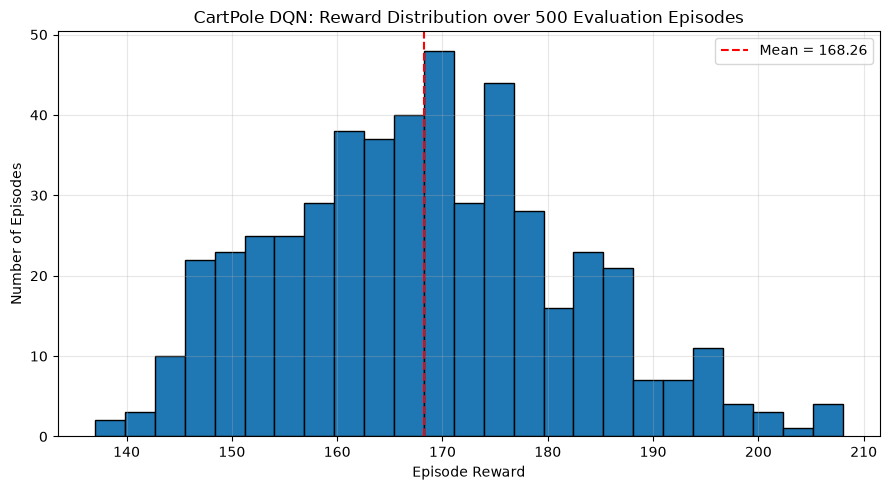

In [6]:



eval_env = gym.make("CartPole-v1")
policy_net.eval()

eval_rewards = []

for episode in range(500):
    state, info = eval_env.reset(seed=10000 + episode)
    total_reward = 0

    for step in range(500):
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = policy_net(state_tensor).argmax(dim=1).item()

        state, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward

        if terminated or truncated:
            break

    eval_rewards.append(total_reward)

eval_env.close()

eval_rewards = np.array(eval_rewards)

print("Evaluation episodes:", len(eval_rewards))
print("Mean reward:", round(eval_rewards.mean(), 2))
print("Standard deviation:", round(eval_rewards.std(), 2))
print("Minimum reward:", eval_rewards.min())
print("Maximum reward:", eval_rewards.max())
print("Episodes reaching 500:", np.sum(eval_rewards == 500))
print("Success rate:", round(np.mean(eval_rewards == 500) * 100, 2), "%")

plt.figure(figsize=(9, 5))
plt.hist(eval_rewards, bins=25, edgecolor="black")
plt.axvline(
    eval_rewards.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {eval_rewards.mean():.2f}"
)
plt.xlabel("Episode Reward")
plt.ylabel("Number of Episodes")
plt.title("CartPole DQN: Reward Distribution over 500 Evaluation Episodes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cartpole_evaluation_histogram.png", dpi=300)
plt.show()

np.save("cartpole_eval_rewards.npy", eval_rewards)


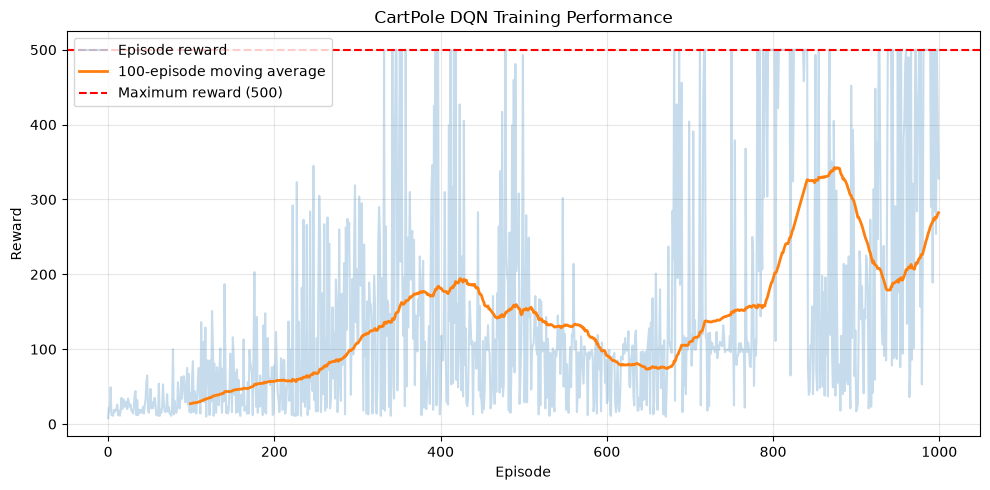

In [7]:



import numpy as np
import matplotlib.pyplot as plt

rewards = np.array(episode_rewards)

moving_avg = np.convolve(
    rewards,
    np.ones(100) / 100,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    rewards,
    alpha=0.25,
    label="Episode reward"
)

plt.plot(
    np.arange(99, len(rewards)),
    moving_avg,
    linewidth=2,
    label="100-episode moving average"
)

plt.axhline(
    y=500,
    color="red",
    linestyle="--",
    label="Maximum reward (500)"
)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("CartPole DQN Training Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("cartpole_training_curve.png", dpi=300)
plt.show()


In [8]:



saved_policy = DQN(state_dim, action_dim).to(device)

saved_policy.load_state_dict(
    torch.load(
        "cartpole_dqn.pth",
        map_location=device,
        weights_only=True
    )
)

saved_policy.eval()

test_env = gym.make("CartPole-v1")
test_rewards = []

for episode in range(100):
    state, info = test_env.reset(seed=20000 + episode)
    total_reward = 0

    for step in range(500):
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = saved_policy(state_tensor).argmax(dim=1).item()

        state, reward, terminated, truncated, info = test_env.step(action)
        total_reward += reward

        if terminated or truncated:
            break

    test_rewards.append(total_reward)

test_env.close()

print("Saved model mean reward:", np.mean(test_rewards))
print("Saved model max reward:", np.max(test_rewards))
print("Saved model success rate:", np.mean(np.array(test_rewards) == 500) * 100, "%")


Saved model mean reward: 167.24
Saved model max reward: 207.0
Saved model success rate: 0.0 %


In [9]:



GAMMA = 0.95
LEARNING_RATE = 0.0005
BATCH_SIZE = 64
BUFFER_SIZE = 50000
TARGET_UPDATE = 10

EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.997

NUM_EPISODES = 2000


policy_net = DQN(state_dim, action_dim).to(device)
target_net = DQN(state_dim, action_dim).to(device)

target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(
    policy_net.parameters(),
    lr=LEARNING_RATE
)

replay_buffer = ReplayBuffer(BUFFER_SIZE)

print("Improved DQN configuration ready!")
print("Device:", device)
print("Learning rate:", LEARNING_RATE)
print("Gamma:", GAMMA)
print("Training episodes:", NUM_EPISODES)


Improved DQN configuration ready!
Device: cuda:0
Learning rate: 0.0005
Gamma: 0.95
Training episodes: 2000


In [10]:

import time

env = gym.make("CartPole-v1")

episode_rewards = []
episode_max_q_values = []
episode_losses = []
episode_history = []

epsilon = EPSILON_START
start_time = time.time()

best_eval_reward = -float("inf")
best_episode = 0

for episode in range(NUM_EPISODES):
    state, info = env.reset(seed=SEED + episode)
    total_reward = 0
    losses = []
    q_values = []

    for step in range(500):
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            max_q = policy_net(state_tensor).max(dim=1).values.item()
            q_values.append(max_q)

        action = select_action(state, epsilon)

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        replay_buffer.push(
            state, action, reward, next_state, done
        )

        loss = optimize_model()
        if loss is not None:
            losses.append(loss)

        state = next_state
        total_reward += reward

        if done:
            break

    episode_rewards.append(total_reward)
    episode_max_q_values.append(np.mean(q_values))
    episode_losses.append(np.mean(losses) if losses else np.nan)
    episode_history.append(episode + 1)

    epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    if (episode + 1) % TARGET_UPDATE == 0:
        target_net.load_state_dict(policy_net.state_dict())

    if (episode + 1) % 50 == 0:
        avg_reward = np.mean(episode_rewards[-100:])
        elapsed = time.time() - start_time

        print(
            f"Episode {episode+1}/{NUM_EPISODES} | "
            f"Avg Reward: {avg_reward:.2f} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Time: {elapsed:.1f}s"
        )

env.close()

print("\nImproved training completed!")
print("Total training time:", round(time.time() - start_time, 2), "seconds")
print("Final 100-episode average reward:", np.mean(episode_rewards[-100:]))

torch.save(policy_net.state_dict(), "cartpole_dqn_improved_final.pth")

np.savez(
    "cartpole_improved_training_stats.npz",
    rewards=np.array(episode_rewards),
    max_q_values=np.array(episode_max_q_values),
    losses=np.array(episode_losses),
    episodes=np.array(episode_history)
)

print("Improved model and training statistics saved!")


Episode 50/2000 | Avg Reward: 27.44 | Epsilon: 0.861 | Time: 1.1s
Episode 100/2000 | Avg Reward: 29.35 | Epsilon: 0.740 | Time: 2.5s
Episode 150/2000 | Avg Reward: 34.34 | Epsilon: 0.637 | Time: 4.1s
Episode 200/2000 | Avg Reward: 40.00 | Epsilon: 0.548 | Time: 5.9s
Episode 250/2000 | Avg Reward: 45.15 | Epsilon: 0.472 | Time: 8.1s
Episode 300/2000 | Avg Reward: 45.55 | Epsilon: 0.406 | Time: 10.0s
Episode 350/2000 | Avg Reward: 50.48 | Epsilon: 0.349 | Time: 12.6s
Episode 400/2000 | Avg Reward: 64.58 | Epsilon: 0.301 | Time: 15.9s
Episode 450/2000 | Avg Reward: 76.91 | Epsilon: 0.259 | Time: 19.7s
Episode 500/2000 | Avg Reward: 84.28 | Epsilon: 0.223 | Time: 23.8s
Episode 550/2000 | Avg Reward: 86.76 | Epsilon: 0.192 | Time: 27.9s
Episode 600/2000 | Avg Reward: 97.14 | Epsilon: 0.165 | Time: 32.9s
Episode 650/2000 | Avg Reward: 98.07 | Epsilon: 0.142 | Time: 37.1s
Episode 700/2000 | Avg Reward: 92.54 | Epsilon: 0.122 | Time: 41.8s
Episode 750/2000 | Avg Reward: 106.35 | Epsilon: 0.105

Evaluation episodes: 500
Mean reward: 99.33
Standard deviation: 8.76
Minimum reward: 12.0
Maximum reward: 107.0
Episodes reaching 500: 0
Success rate: 0.0 %


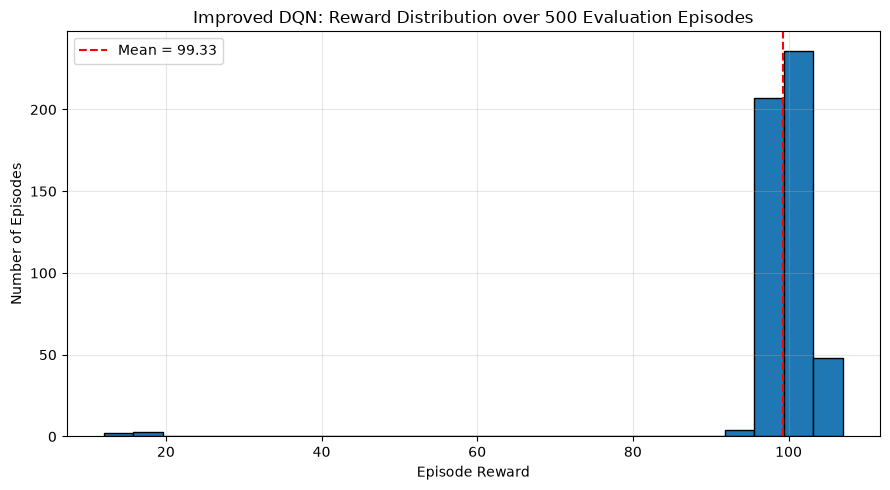

In [11]:

eval_env = gym.make("CartPole-v1")
policy_net.eval()

improved_eval_rewards = []

for episode in range(500):
    state, info = eval_env.reset(seed=30000 + episode)
    total_reward = 0

    for step in range(500):
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = policy_net(state_tensor).argmax(dim=1).item()

        state, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward

        if terminated or truncated:
            break

    improved_eval_rewards.append(total_reward)

eval_env.close()

improved_eval_rewards = np.array(improved_eval_rewards)

print("Evaluation episodes:", len(improved_eval_rewards))
print("Mean reward:", round(improved_eval_rewards.mean(), 2))
print("Standard deviation:", round(improved_eval_rewards.std(), 2))
print("Minimum reward:", improved_eval_rewards.min())
print("Maximum reward:", improved_eval_rewards.max())
print("Episodes reaching 500:", np.sum(improved_eval_rewards == 500))
print("Success rate:", round(np.mean(improved_eval_rewards == 500) * 100, 2), "%")

plt.figure(figsize=(9, 5))
plt.hist(improved_eval_rewards, bins=25, edgecolor="black")
plt.axvline(
    improved_eval_rewards.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {improved_eval_rewards.mean():.2f}"
)
plt.xlabel("Episode Reward")
plt.ylabel("Number of Episodes")
plt.title("Improved DQN: Reward Distribution over 500 Evaluation Episodes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cartpole_improved_evaluation_histogram.png", dpi=300)
plt.show()

np.save("cartpole_improved_eval_rewards.npy", improved_eval_rewards)


In [12]:



GAMMA = 0.95
LEARNING_RATE = 0.0003
BATCH_SIZE = 64
BUFFER_SIZE = 50000
TARGET_UPDATE = 20

EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.998

NUM_EPISODES = 2500

policy_net = DQN(state_dim, action_dim).to(device)
target_net = DQN(state_dim, action_dim).to(device)

target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(
    policy_net.parameters(),
    lr=LEARNING_RATE
)

replay_buffer = ReplayBuffer(BUFFER_SIZE)

print("Double DQN configuration ready!")
print("Device:", device)
print("Episodes:", NUM_EPISODES)
print("Learning rate:", LEARNING_RATE)
print("Target update interval:", TARGET_UPDATE)


Double DQN configuration ready!
Device: cuda:0
Episodes: 2500
Learning rate: 0.0003
Target update interval: 20


In [13]:

def optimize_model():
    if len(replay_buffer) < BATCH_SIZE:
        return None

    states, actions, rewards, next_states, dones = (
        replay_buffer.sample(BATCH_SIZE)
    )

    current_q = policy_net(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    with torch.no_grad():
        next_actions = policy_net(next_states).argmax(
            dim=1, keepdim=True
        )

        next_q = target_net(next_states).gather(
            1, next_actions
        ).squeeze(1)

        target_q = rewards + GAMMA * next_q * (1 - dones)

    loss = nn.functional.smooth_l1_loss(
        current_q, target_q
    )

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        policy_net.parameters(),
        max_norm=10.0
    )

    optimizer.step()

    return loss.item()

print("Double DQN optimization function ready!")


Double DQN optimization function ready!


In [14]:

import time
import copy

train_env = gym.make("CartPole-v1")

ddqn_rewards = []
ddqn_max_q_values = []
ddqn_losses = []
ddqn_epsilons = []

best_eval_reward = -float("inf")
best_episode = 0
start_time = time.time()

def evaluate_checkpoint(model, n_episodes=20):
    model.eval()
    rewards = []

    for i in range(n_episodes):
        state, _ = train_env.reset(seed=40000 + i)
        total_reward = 0

        for _ in range(500):
            state_tensor = torch.as_tensor(
                state, dtype=torch.float32, device=device
            ).unsqueeze(0)

            with torch.no_grad():
                action = model(state_tensor).argmax(dim=1).item()

            state, reward, terminated, truncated, _ = train_env.step(action)
            total_reward += reward

            if terminated or truncated:
                break

        rewards.append(total_reward)

    return float(np.mean(rewards))

for episode in range(NUM_EPISODES):
    state, _ = train_env.reset(seed=SEED + episode)
    total_reward = 0
    episode_losses = []
    episode_q_values = []

    epsilon = max(
        EPSILON_END,
        EPSILON_START * (EPSILON_DECAY ** episode)
    )

    for step in range(500):
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            q_values = policy_net(state_tensor)
            episode_q_values.append(q_values.max().item())

        if random.random() < epsilon:
            action = train_env.action_space.sample()
        else:
            action = q_values.argmax(dim=1).item()

        next_state, reward, terminated, truncated, _ = train_env.step(action)
        done = terminated or truncated

        replay_buffer.push(
            state, action, reward, next_state, terminated
        )

        loss = optimize_model()

        if loss is not None:
            episode_losses.append(loss)

        state = next_state
        total_reward += reward

        if done:
            break

    ddqn_rewards.append(total_reward)
    ddqn_max_q_values.append(max(episode_q_values))
    ddqn_losses.append(
        np.mean(episode_losses) if episode_losses else np.nan
    )
    ddqn_epsilons.append(epsilon)

    if (episode + 1) % TARGET_UPDATE == 0:
        target_net.load_state_dict(policy_net.state_dict())


    if (episode + 1) % 50 == 0:
        eval_mean = evaluate_checkpoint(policy_net)

        if eval_mean > best_eval_reward:
            best_eval_reward = eval_mean
            best_episode = episode + 1

            torch.save(
                policy_net.state_dict(),
                "cartpole_ddqn_best.pth"
            )

        recent_avg = np.mean(ddqn_rewards[-100:])

        print(
            f"Episode {episode+1}/{NUM_EPISODES} | "
            f"Train Avg: {recent_avg:.2f} | "
            f"Eval: {eval_mean:.2f} | "
            f"Best Eval: {best_eval_reward:.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

train_env.close()

torch.save(
    policy_net.state_dict(),
    "cartpole_ddqn_final.pth"
)

np.savez(
    "cartpole_ddqn_training_stats.npz",
    rewards=np.array(ddqn_rewards),
    max_q_values=np.array(ddqn_max_q_values),
    losses=np.array(ddqn_losses),
    epsilons=np.array(ddqn_epsilons)
)

print("\nTraining completed!")
print("Total time:", round(time.time() - start_time, 2), "seconds")
print("Best checkpoint episode:", best_episode)
print("Best checkpoint evaluation mean:", best_eval_reward)
print("Final 100-episode training average:",
      np.mean(ddqn_rewards[-100:]))


Episode 50/2500 | Train Avg: 21.54 | Eval: 44.70 | Best Eval: 44.70 | Epsilon: 0.907
Episode 100/2500 | Train Avg: 21.97 | Eval: 100.70 | Best Eval: 100.70 | Epsilon: 0.820
Episode 150/2500 | Train Avg: 28.19 | Eval: 140.80 | Best Eval: 140.80 | Epsilon: 0.742
Episode 200/2500 | Train Avg: 36.77 | Eval: 256.20 | Best Eval: 256.20 | Epsilon: 0.671
Episode 250/2500 | Train Avg: 51.01 | Eval: 131.45 | Best Eval: 256.20 | Epsilon: 0.607
Episode 300/2500 | Train Avg: 56.86 | Eval: 167.60 | Best Eval: 256.20 | Epsilon: 0.550
Episode 350/2500 | Train Avg: 51.81 | Eval: 96.65 | Best Eval: 256.20 | Epsilon: 0.497
Episode 400/2500 | Train Avg: 48.23 | Eval: 105.20 | Best Eval: 256.20 | Epsilon: 0.450
Episode 450/2500 | Train Avg: 45.46 | Eval: 104.40 | Best Eval: 256.20 | Epsilon: 0.407
Episode 500/2500 | Train Avg: 41.53 | Eval: 106.95 | Best Eval: 256.20 | Epsilon: 0.368
Episode 550/2500 | Train Avg: 55.07 | Eval: 105.55 | Best Eval: 256.20 | Epsilon: 0.333
Episode 600/2500 | Train Avg: 83.40 

In [15]:

best_policy = DQN(state_dim, action_dim).to(device)

best_policy.load_state_dict(
    torch.load(
        "cartpole_ddqn_best.pth",
        map_location=device,
        weights_only=True
    )
)

best_policy.eval()

eval_env = gym.make("CartPole-v1")
best_eval_rewards = []

for episode in range(500):
    state, _ = eval_env.reset(seed=50000 + episode)
    total_reward = 0

    for step in range(500):
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = best_policy(state_tensor).argmax(dim=1).item()

        state, reward, terminated, truncated, _ = eval_env.step(action)
        total_reward += reward

        if terminated or truncated:
            break

    best_eval_rewards.append(total_reward)

eval_env.close()

best_eval_rewards = np.array(best_eval_rewards)

print("Evaluation episodes:", len(best_eval_rewards))
print("Mean reward:", round(best_eval_rewards.mean(), 2))
print("Standard deviation:", round(best_eval_rewards.std(), 2))
print("Minimum reward:", best_eval_rewards.min())
print("Maximum reward:", best_eval_rewards.max())
print("Episodes reaching 500:", np.sum(best_eval_rewards == 500))
print("Success rate:", round(np.mean(best_eval_rewards == 500) * 100, 2), "%")

np.save("cartpole_ddqn_best_eval_rewards.npy", best_eval_rewards)


Evaluation episodes: 500
Mean reward: 500.0
Standard deviation: 0.0
Minimum reward: 500.0
Maximum reward: 500.0
Episodes reaching 500: 500
Success rate: 100.0 %


In [16]:


for name in [
    "episode_rewards",
    "episode_max_q_values",
    "max_q_values",
    "q_values_history",
    "episode_history",
    "improved_episode_rewards",
    "improved_max_q_values"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: available, length = {len(value)}")
    else:
        print(f"{name}: not found")


episode_rewards: available, length = 2000
episode_max_q_values: available, length = 2000
max_q_values: available, length = 328
q_values_history: not found
episode_history: available, length = 2000
improved_episode_rewards: not found
improved_max_q_values: not found


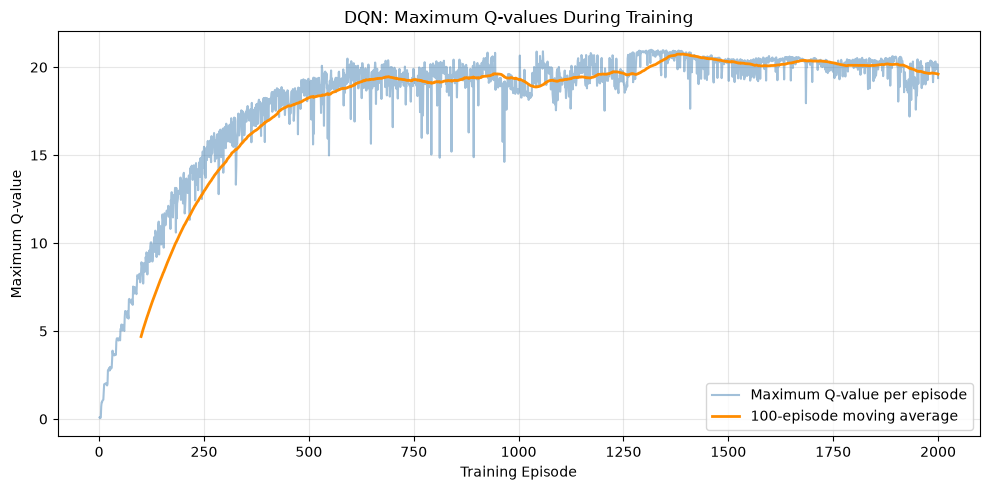

In [17]:

import numpy as np
import matplotlib.pyplot as plt

q_values = np.array(episode_max_q_values, dtype=float)
episodes = np.arange(1, len(q_values) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    q_values,
    color="steelblue",
    alpha=0.5,
    label="Maximum Q-value per episode"
)

window = 100
moving_avg = np.convolve(
    q_values,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(
    episodes[window - 1:],
    moving_avg,
    color="darkorange",
    linewidth=2,
    label="100-episode moving average"
)

plt.xlabel("Training Episode")
plt.ylabel("Maximum Q-value")
plt.title("DQN: Maximum Q-values During Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("cartpole_max_q_values.png", dpi=300)
plt.show()


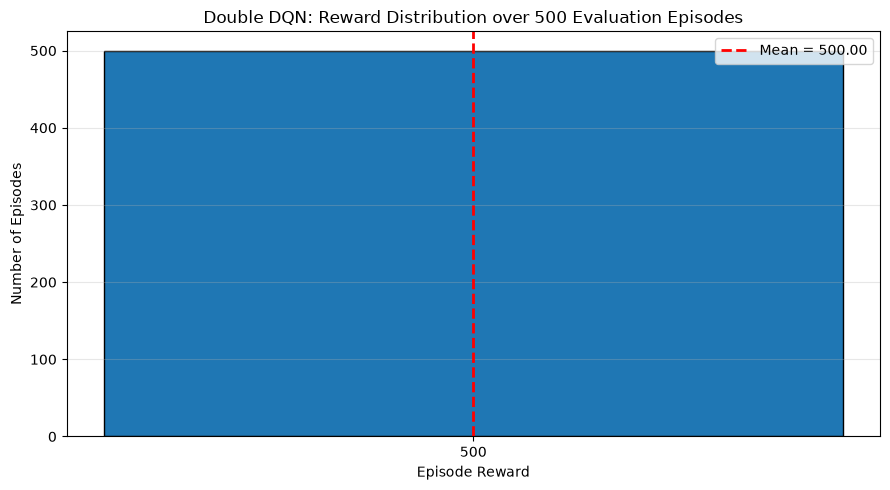

Mean reward: 500.0
Standard deviation: 0.0


In [18]:

import numpy as np
import matplotlib.pyplot as plt

rewards = np.load("cartpole_ddqn_best_eval_rewards.npy")

plt.figure(figsize=(9, 5))

plt.hist(
    rewards,
    bins=np.arange(499.5, 501.5, 1),
    edgecolor="black"
)

plt.axvline(
    rewards.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {rewards.mean():.2f}"
)

plt.xlabel("Episode Reward")
plt.ylabel("Number of Episodes")
plt.title("Double DQN: Reward Distribution over 500 Evaluation Episodes")
plt.xticks([500])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("cartpole_ddqn_best_histogram.png", dpi=300)
plt.show()

print("Mean reward:", rewards.mean())
print("Standard deviation:", rewards.std())


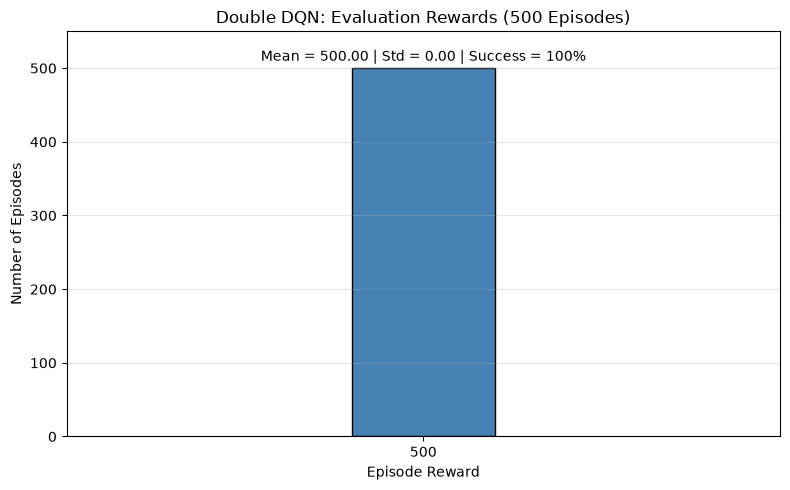

In [19]:

plt.figure(figsize=(8, 5))

plt.bar(
    [500],
    [len(rewards)],
    width=0.6,
    color="steelblue",
    edgecolor="black"
)

plt.xlim(498.5, 501.5)
plt.ylim(0, 550)
plt.xticks([500])

plt.xlabel("Episode Reward")
plt.ylabel("Number of Episodes")
plt.title("Double DQN: Evaluation Rewards (500 Episodes)")

plt.text(
    500, 510,
    "Mean = 500.00 | Std = 0.00 | Success = 100%",
    ha="center",
    fontsize=10
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("cartpole_ddqn_best_histogram.png", dpi=300)
plt.show()


Observation shape: (210, 160, 3)
Observation dtype: uint8
Number of actions: 9
Action meanings: ['NOOP', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT']


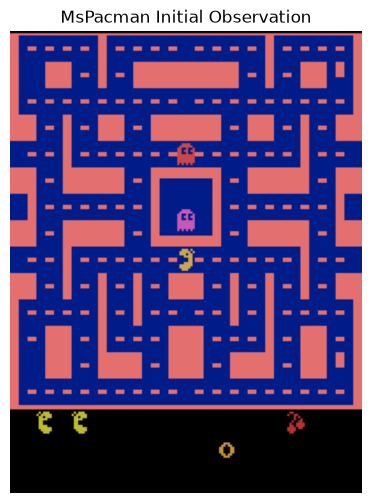

In [20]:
import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt

gym.register_envs(ale_py)

env = gym.make("ALE/MsPacman-v5")

obs, info = env.reset(seed=42)

print("Observation shape:", obs.shape)
print("Observation dtype:", obs.dtype)
print("Number of actions:", env.action_space.n)
print("Action meanings:", env.unwrapped.get_action_meanings())

plt.figure(figsize=(5, 6))
plt.imshow(obs)
plt.axis("off")
plt.title("MsPacman Initial Observation")
plt.show()

env.close()

In [23]:
import cv2
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


Preprocessed observation shape: (4, 84, 84)
Observation dtype: uint8
Minimum pixel value: 0
Maximum pixel value: 172
Number of actions: 9


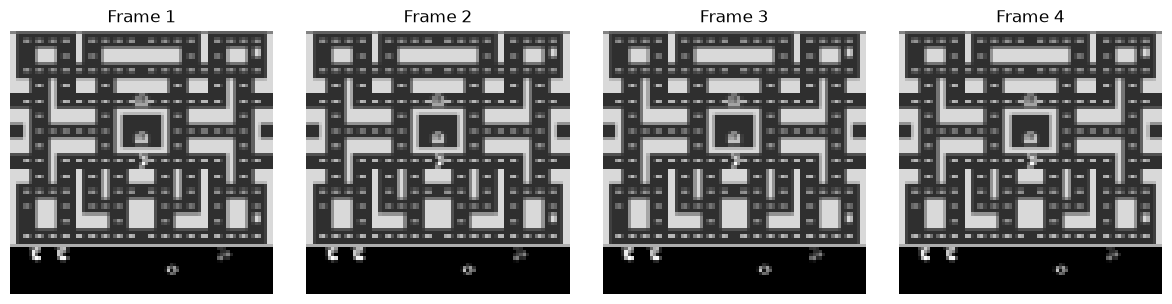

In [24]:
import gymnasium as gym
from gymnasium.wrappers import (
    AtariPreprocessing,
    FrameStackObservation
)
import numpy as np
import matplotlib.pyplot as plt

env = gym.make(
    "ALE/MsPacman-v5",
    frameskip=1
)

env = AtariPreprocessing(
    env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

env = FrameStackObservation(env, stack_size=4)

state, info = env.reset(seed=42)

print("Preprocessed observation shape:", state.shape)
print("Observation dtype:", state.dtype)
print("Minimum pixel value:", np.min(state))
print("Maximum pixel value:", np.max(state))
print("Number of actions:", env.action_space.n)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    axes[i].imshow(state[i], cmap="gray")
    axes[i].set_title(f"Frame {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

env.close()

In [25]:

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class AtariDQN(nn.Module):
    def __init__(self, num_actions):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(3136, 512),
            nn.ReLU(),
            nn.Linear(512, num_actions)
        )

    def forward(self, x):
        x = x.float() / 255.0
        return self.network(x)

num_actions = 9

policy_net_atari = AtariDQN(num_actions).to(device)
target_net_atari = AtariDQN(num_actions).to(device)

target_net_atari.load_state_dict(policy_net_atari.state_dict())
target_net_atari.eval()

test_input = torch.as_tensor(
    state.copy(), dtype=torch.float32, device=device
).unsqueeze(0)

with torch.no_grad():
    output = policy_net_atari(test_input)

print("Device:", device)
print("Input shape:", test_input.shape)
print("Output shape:", output.shape)
print("Number of parameters:",
      sum(p.numel() for p in policy_net_atari.parameters()))


Device: cuda
Input shape: torch.Size([1, 4, 84, 84])
Output shape: torch.Size([1, 9])
Number of parameters: 1688745


In [26]:

import random
from collections import deque
import numpy as np
import torch

class AtariReplayBuffer:
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((
            np.array(state, dtype=np.uint8, copy=True),
            int(action),
            float(reward),
            np.array(next_state, dtype=np.uint8, copy=True),
            bool(done)
        ))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            torch.from_numpy(np.stack(states)).to(device),
            torch.tensor(actions, dtype=torch.long, device=device),
            torch.tensor(rewards, dtype=torch.float32, device=device),
            torch.from_numpy(np.stack(next_states)).to(device),
            torch.tensor(dones, dtype=torch.float32, device=device)
        )

    def __len__(self):
        return len(self.buffer)


atari_replay_buffer = AtariReplayBuffer(capacity=10000)

# Test the replay buffer
dummy_state = np.zeros((4, 84, 84), dtype=np.uint8)

for i in range(100):
    atari_replay_buffer.push(
        dummy_state,
        i % 9,
        1.0,
        dummy_state,
        False
    )

batch = atari_replay_buffer.sample(32)

print("Replay buffer size:", len(atari_replay_buffer))
print("States shape:", batch[0].shape)
print("Actions shape:", batch[1].shape)
print("Rewards shape:", batch[2].shape)
print("Next states shape:", batch[3].shape)
print("Dones shape:", batch[4].shape)
print("Device:", batch[0].device)


Replay buffer size: 100
States shape: torch.Size([32, 4, 84, 84])
Actions shape: torch.Size([32])
Rewards shape: torch.Size([32])
Next states shape: torch.Size([32, 4, 84, 84])
Dones shape: torch.Size([32])
Device: cuda:0


In [27]:

import torch.optim as optim
import torch.nn.functional as F

ATARI_GAMMA = 0.99
ATARI_LR = 1e-4
ATARI_BATCH_SIZE = 32

atari_optimizer = optim.Adam(
    policy_net_atari.parameters(),
    lr=ATARI_LR
)

def optimize_atari_model():
    if len(atari_replay_buffer) < ATARI_BATCH_SIZE:
        return None

    states, actions, rewards, next_states, dones = (
        atari_replay_buffer.sample(ATARI_BATCH_SIZE)
    )

    current_q = policy_net_atari(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    with torch.no_grad():
        next_q = target_net_atari(next_states).max(dim=1).values
        target_q = rewards + ATARI_GAMMA * next_q * (1 - dones)

    loss = F.smooth_l1_loss(current_q, target_q)

    atari_optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        policy_net_atari.parameters(),
        max_norm=10.0
    )

    atari_optimizer.step()

    return loss.item()


test_loss = optimize_atari_model()

print("Optimization test successful!")
print("Loss:", test_loss)
print("Device:", device)


Optimization test successful!
Loss: 0.5309618711471558
Device: cuda


In [28]:

import random
import numpy as np
import torch
import torch.optim as optim

ATARI_GAMMA = 0.99
ATARI_LR = 1e-4
ATARI_BATCH_SIZE = 32

ATARI_BUFFER_SIZE = 10000
ATARI_TARGET_UPDATE = 1000
ATARI_LEARNING_STARTS = 1000
ATARI_TRAIN_FREQUENCY = 4

ATARI_EPS_START = 1.0
ATARI_EPS_END = 0.1
ATARI_EPS_DECAY_STEPS = 100000

ATARI_NUM_EPISODES = 5


policy_net_atari = AtariDQN(num_actions).to(device)
target_net_atari = AtariDQN(num_actions).to(device)

target_net_atari.load_state_dict(
    policy_net_atari.state_dict()
)
target_net_atari.eval()


atari_optimizer = optim.Adam(
    policy_net_atari.parameters(),
    lr=ATARI_LR
)


atari_replay_buffer = AtariReplayBuffer(
    capacity=ATARI_BUFFER_SIZE
)

def get_atari_epsilon(step):
    fraction = min(step / ATARI_EPS_DECAY_STEPS, 1.0)
    return ATARI_EPS_START + fraction * (
        ATARI_EPS_END - ATARI_EPS_START
    )

def select_atari_action(state, epsilon):
    if random.random() < epsilon:
        return random.randrange(num_actions)

    state_tensor = torch.as_tensor(
        np.asarray(state),
        device=device
    ).unsqueeze(0)

    with torch.no_grad():
        q_values = policy_net_atari(state_tensor)

    return q_values.argmax(dim=1).item()

print("Training configuration ready!")
print("Device:", device)
print("Test episodes:", ATARI_NUM_EPISODES)
print("Replay buffer size:", len(atari_replay_buffer))
print("Initial epsilon:", get_atari_epsilon(0))
print("Epsilon after 100,000 steps:",
      get_atari_epsilon(100000))


Training configuration ready!
Device: cuda
Test episodes: 5
Replay buffer size: 0
Initial epsilon: 1.0
Epsilon after 100,000 steps: 0.09999999999999998


In [30]:

import time

env = gym.make("ALE/MsPacman-v5", frameskip=1)

env = AtariPreprocessing(
    env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

env = FrameStackObservation(env, stack_size=4)

atari_episode_rewards = []
atari_losses = []
global_step = 0

start_time = time.time()

for episode in range(ATARI_NUM_EPISODES):
    state, info = env.reset(seed=42 + episode)
    episode_reward = 0
    episode_losses = []

    done = False

    while not done:
        epsilon = get_atari_epsilon(global_step)

        action = select_atari_action(state, epsilon)

        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        atari_replay_buffer.push(
            np.asarray(state),
            action,
            reward,
            np.asarray(next_state),
            done
        )

        state = next_state
        episode_reward += reward
        global_step += 1

        if (
            global_step >= ATARI_LEARNING_STARTS
            and global_step % ATARI_TRAIN_FREQUENCY == 0
        ):
            loss = optimize_atari_model()

            if loss is not None:
                episode_losses.append(loss)
                atari_losses.append(loss)

        if global_step % ATARI_TARGET_UPDATE == 0:
            target_net_atari.load_state_dict(
                policy_net_atari.state_dict()
            )

    atari_episode_rewards.append(episode_reward)

    avg_loss = (
        np.mean(episode_losses)
        if episode_losses else float("nan")
    )

    print(
        f"Episode {episode + 1}/{ATARI_NUM_EPISODES} | "
        f"Reward: {episode_reward:.0f} | "
        f"Steps: {global_step} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Avg Loss: {avg_loss:.4f}"
    )

env.close()

print("\nTraining test completed!")
print("Total steps:", global_step)
print("Replay buffer size:", len(atari_replay_buffer))
print("Optimization updates:", len(atari_losses))
print("Mean episode reward:", np.mean(atari_episode_rewards))
print("Elapsed time:", round(time.time() - start_time, 2), "seconds")


Episode 1/5 | Reward: 260 | Steps: 526 | Epsilon: 0.995 | Avg Loss: nan
Episode 2/5 | Reward: 160 | Steps: 915 | Epsilon: 0.992 | Avg Loss: nan
Episode 3/5 | Reward: 140 | Steps: 1325 | Epsilon: 0.988 | Avg Loss: 0.3727
Episode 4/5 | Reward: 350 | Steps: 1837 | Epsilon: 0.983 | Avg Loss: 0.4650
Episode 5/5 | Reward: 280 | Steps: 2287 | Epsilon: 0.979 | Avg Loss: 0.4471

Training test completed!
Total steps: 2287
Replay buffer size: 2287
Optimization updates: 322
Mean episode reward: 238.0
Elapsed time: 1.81 seconds


In [31]:



ATARI_NUM_EPISODES = 1000
ATARI_GAMMA = 0.99
ATARI_LEARNING_RATE = 0.0001
ATARI_BATCH_SIZE = 32
ATARI_BUFFER_SIZE = 100000

ATARI_LEARNING_STARTS = 10000
ATARI_TRAIN_FREQUENCY = 4
ATARI_TARGET_UPDATE = 10000

ATARI_EPS_START = 1.0
ATARI_EPS_END = 0.1
ATARI_EPS_DECAY_STEPS = 100000


policy_net_atari = AtariDQN(num_actions).to(device)
target_net_atari = AtariDQN(num_actions).to(device)

target_net_atari.load_state_dict(
    policy_net_atari.state_dict()
)
target_net_atari.eval()


atari_optimizer = optim.Adam(
    policy_net_atari.parameters(),
    lr=ATARI_LEARNING_RATE
)


atari_replay_buffer = AtariReplayBuffer(
    capacity=ATARI_BUFFER_SIZE
)


atari_episode_rewards = []
atari_losses = []
global_step = 0

print("Full training configuration ready!")
print("Device:", device)
print("Episodes:", ATARI_NUM_EPISODES)
print("Learning rate:", ATARI_LEARNING_RATE)
print("Replay buffer capacity:", ATARI_BUFFER_SIZE)
print("Learning starts:", ATARI_LEARNING_STARTS)
print("Replay buffer size:", len(atari_replay_buffer))


Full training configuration ready!
Device: cuda
Episodes: 1000
Learning rate: 0.0001
Replay buffer capacity: 100000
Learning starts: 10000
Replay buffer size: 0


In [32]:

import time
import os

os.makedirs("atari_checkpoints", exist_ok=True)

env = gym.make("ALE/MsPacman-v5", frameskip=1)

env = AtariPreprocessing(
    env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

env = FrameStackObservation(env, stack_size=4)

start_time = time.time()
best_avg_reward = -float("inf")

for episode in range(ATARI_NUM_EPISODES):
    state, info = env.reset()
    episode_reward = 0
    episode_losses = []
    done = False

    while not done:
        epsilon = get_atari_epsilon(global_step)
        action = select_atari_action(state, epsilon)

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        atari_replay_buffer.push(
            np.asarray(state),
            action,
            reward,
            np.asarray(next_state),
            done
        )

        state = next_state
        episode_reward += reward
        global_step += 1

        if (
            global_step >= ATARI_LEARNING_STARTS
            and global_step % ATARI_TRAIN_FREQUENCY == 0
        ):
            loss = optimize_atari_model()

            if loss is not None:
                episode_losses.append(loss)
                atari_losses.append(loss)

        if global_step % ATARI_TARGET_UPDATE == 0:
            target_net_atari.load_state_dict(
                policy_net_atari.state_dict()
            )

    atari_episode_rewards.append(episode_reward)

    if (episode + 1) % 10 == 0:
        avg_reward = np.mean(atari_episode_rewards[-10:])

        print(
            f"Episode {episode+1}/{ATARI_NUM_EPISODES} | "
            f"Avg Reward: {avg_reward:.2f} | "
            f"Steps: {global_step} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Time: {time.time()-start_time:.1f}s"
        )

        if avg_reward > best_avg_reward:
            best_avg_reward = avg_reward
            torch.save(
                policy_net_atari.state_dict(),
                "atari_checkpoints/mspacman_best.pth"
            )

    if (episode + 1) % 100 == 0:
        torch.save(
            {
                "episode": episode + 1,
                "global_step": global_step,
                "policy_net": policy_net_atari.state_dict(),
                "target_net": target_net_atari.state_dict(),
                "optimizer": atari_optimizer.state_dict(),
                "episode_rewards": atari_episode_rewards,
                "losses": atari_losses
            },
            f"atari_checkpoints/mspacman_episode_{episode+1}.pth"
        )

env.close()

torch.save(
    policy_net_atari.state_dict(),
    "atari_checkpoints/mspacman_final.pth"
)

np.save(
    "atari_episode_rewards.npy",
    np.array(atari_episode_rewards)
)

print("\nFull training completed!")
print("Total steps:", global_step)
print("Best 10-episode average reward:", best_avg_reward)
print("Final 100-episode average reward:",
      np.mean(atari_episode_rewards[-100:]))
print("Total time:", round(time.time()-start_time, 2), "seconds")


Episode 10/1000 | Avg Reward: 229.00 | Steps: 4773 | Epsilon: 0.957 | Time: 1.7s
Episode 20/1000 | Avg Reward: 223.00 | Steps: 9659 | Epsilon: 0.913 | Time: 3.6s
Episode 30/1000 | Avg Reward: 402.00 | Steps: 14922 | Epsilon: 0.866 | Time: 8.0s
Episode 40/1000 | Avg Reward: 238.00 | Steps: 19865 | Epsilon: 0.821 | Time: 12.3s
Episode 50/1000 | Avg Reward: 267.00 | Steps: 24822 | Epsilon: 0.777 | Time: 16.8s
Episode 60/1000 | Avg Reward: 338.00 | Steps: 30114 | Epsilon: 0.729 | Time: 21.5s
Episode 70/1000 | Avg Reward: 385.00 | Steps: 35297 | Epsilon: 0.682 | Time: 26.4s
Episode 80/1000 | Avg Reward: 395.00 | Steps: 40531 | Epsilon: 0.635 | Time: 31.2s
Episode 90/1000 | Avg Reward: 464.00 | Steps: 46512 | Epsilon: 0.581 | Time: 36.8s
Episode 100/1000 | Avg Reward: 485.00 | Steps: 52483 | Epsilon: 0.528 | Time: 42.6s
Episode 110/1000 | Avg Reward: 428.00 | Steps: 58197 | Epsilon: 0.476 | Time: 48.6s
Episode 120/1000 | Avg Reward: 473.00 | Steps: 64444 | Epsilon: 0.420 | Time: 54.8s
Episod

Episode 970/1000 | Avg Reward: 731.00 | Steps: 611279 | Epsilon: 0.100 | Time: 641.2s
Episode 980/1000 | Avg Reward: 761.00 | Steps: 618127 | Epsilon: 0.100 | Time: 648.4s
Episode 990/1000 | Avg Reward: 781.00 | Steps: 624624 | Epsilon: 0.100 | Time: 655.3s
Episode 1000/1000 | Avg Reward: 629.00 | Steps: 630209 | Epsilon: 0.100 | Time: 661.4s

Full training completed!
Total steps: 630209
Best 10-episode average reward: 1355.0
Final 100-episode average reward: 746.4
Total time: 661.85 seconds


In [33]:



best_atari_policy = AtariDQN(num_actions).to(device)

best_atari_policy.load_state_dict(
    torch.load(
        "atari_checkpoints/mspacman_best.pth",
        map_location=device,
        weights_only=True
    )
)

best_atari_policy.eval()

eval_env = gym.make("ALE/MsPacman-v5", frameskip=1)

eval_env = AtariPreprocessing(
    eval_env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

eval_env = FrameStackObservation(eval_env, stack_size=4)

atari_eval_rewards = []

for episode in range(100):
    state, info = eval_env.reset(seed=50000 + episode)
    total_reward = 0
    done = False

    while not done:
        state_tensor = torch.as_tensor(
            np.asarray(state),
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = best_atari_policy(
                state_tensor
            ).argmax(dim=1).item()

        state, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward
        done = terminated or truncated

    atari_eval_rewards.append(total_reward)

    if (episode + 1) % 20 == 0:
        print(f"Evaluated {episode + 1}/100 episodes")

eval_env.close()

atari_eval_rewards = np.array(atari_eval_rewards)

print("\nBest MsPacman Model Evaluation")
print("Evaluation episodes:", len(atari_eval_rewards))
print("Mean reward:", round(atari_eval_rewards.mean(), 2))
print("Standard deviation:", round(atari_eval_rewards.std(), 2))
print("Minimum reward:", atari_eval_rewards.min())
print("Maximum reward:", atari_eval_rewards.max())

np.save("mspacman_best_eval_rewards.npy", atari_eval_rewards)


Evaluated 20/100 episodes
Evaluated 40/100 episodes
Evaluated 60/100 episodes
Evaluated 80/100 episodes
Evaluated 100/100 episodes

Best MsPacman Model Evaluation
Evaluation episodes: 100
Mean reward: 592.3
Standard deviation: 201.3
Minimum reward: 360.0
Maximum reward: 1480.0


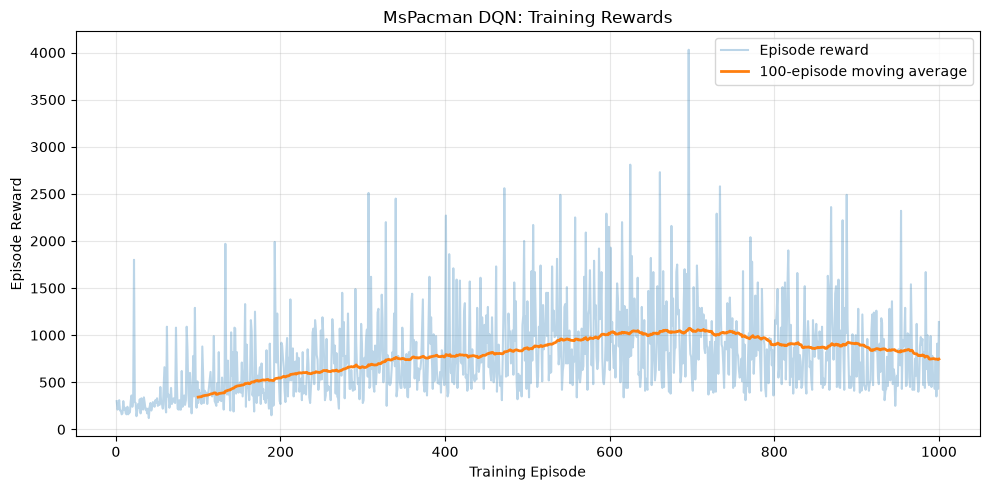

In [34]:


import numpy as np
import matplotlib.pyplot as plt

rewards = np.array(atari_episode_rewards)

window = 100
moving_avg = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(rewards) + 1),
    rewards,
    alpha=0.3,
    label="Episode reward"
)

plt.plot(
    np.arange(window, len(rewards) + 1),
    moving_avg,
    linewidth=2,
    label="100-episode moving average"
)

plt.xlabel("Training Episode")
plt.ylabel("Episode Reward")
plt.title("MsPacman DQN: Training Rewards")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("mspacman_training_rewards.png", dpi=300)
plt.show()


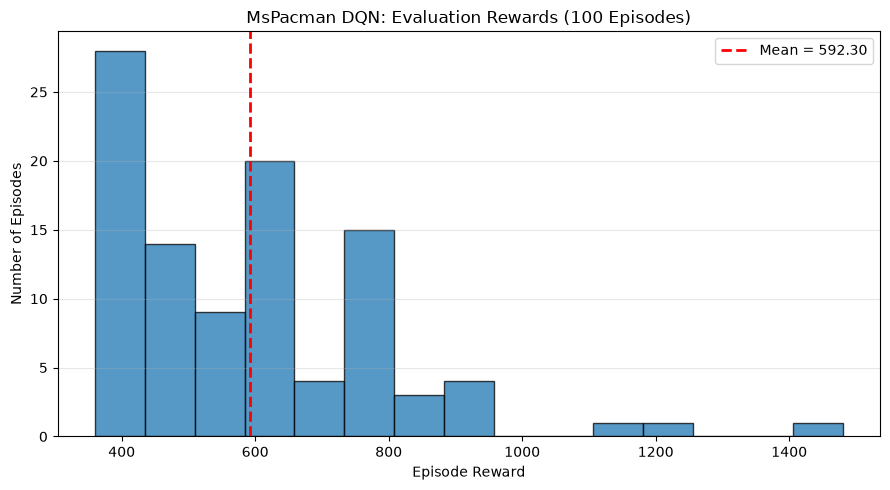

Mean reward: 592.3
Standard deviation: 201.3
Minimum reward: 360.0
Maximum reward: 1480.0


In [35]:



import numpy as np
import matplotlib.pyplot as plt

rewards = np.array(atari_eval_rewards)

plt.figure(figsize=(9, 5))

plt.hist(
    rewards,
    bins=15,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    rewards.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {rewards.mean():.2f}"
)

plt.xlabel("Episode Reward")
plt.ylabel("Number of Episodes")
plt.title("MsPacman DQN: Evaluation Rewards (100 Episodes)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("mspacman_eval_histogram.png", dpi=300)
plt.show()

print("Mean reward:", round(rewards.mean(), 2))
print("Standard deviation:", round(rewards.std(), 2))
print("Minimum reward:", rewards.min())
print("Maximum reward:", rewards.max())


In [36]:

import pandas as pd

results = pd.DataFrame({
    "Environment": [
        "CartPole-v1",
        "CartPole-v1",
        "MsPacman-v5"
    ],
    "Model": [
        "Improved DQN",
        "Double DQN",
        "Atari DQN"
    ],
    "Evaluation Episodes": [500, 500, 100],
    "Mean Reward": [99.33, 500.0, 592.3],
    "Std Deviation": [8.76, 0.0, 201.3],
    "Min Reward": [12.0, 500.0, 360.0],
    "Max Reward": [107.0, 500.0, 1480.0]
})

display(results)

results.to_csv("dqn_final_results.csv", index=False)


,Environment,Model,Evaluation Episodes,Mean Reward,Std Deviation,Min Reward,Max Reward
0,CartPole-v1,Improved DQN,500,99.33,8.76,12.0,107.0
1,CartPole-v1,Double DQN,500,500.00,0.00,500.0,500.0
2,MsPacman-v5,Atari DQN,100,592.30,201.30,360.0,1480.0


In [37]:



import numpy as np
import torch
import gymnasium as gym
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation


eval_env = gym.make("ALE/MsPacman-v5", frameskip=1)

eval_env = AtariPreprocessing(
    eval_env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

eval_env = FrameStackObservation(eval_env, stack_size=4)


best_atari_policy = AtariDQN(num_actions).to(device)

checkpoint = torch.load(
    "atari_checkpoints/mspacman_best.pth",
    map_location=device,
    weights_only=True
)

best_atari_policy.load_state_dict(checkpoint)
best_atari_policy.eval()


atari_eval_rewards_500 = []

for episode in range(500):
    state, info = eval_env.reset(seed=50000 + episode)
    total_reward = 0
    done = False

    while not done:
        state_tensor = torch.as_tensor(
            np.asarray(state),
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        with torch.no_grad():
            action = best_atari_policy(
                state_tensor
            ).argmax(dim=1).item()

        state, reward, terminated, truncated, info = (
            eval_env.step(action)
        )

        total_reward += reward
        done = terminated or truncated

    atari_eval_rewards_500.append(total_reward)

    if (episode + 1) % 50 == 0:
        print(f"Evaluated {episode + 1}/500 episodes")

eval_env.close()

atari_eval_rewards_500 = np.array(atari_eval_rewards_500)

print("\nEvaluation complete!")
print("Episodes:", len(atari_eval_rewards_500))
print("Mean reward:", round(atari_eval_rewards_500.mean(), 2))
print("Standard deviation:", round(atari_eval_rewards_500.std(), 2))
print("Minimum reward:", atari_eval_rewards_500.min())
print("Maximum reward:", atari_eval_rewards_500.max())

np.save(
    "mspacman_eval_rewards_500.npy",
    atari_eval_rewards_500
)


Evaluated 50/500 episodes
Evaluated 100/500 episodes
Evaluated 150/500 episodes
Evaluated 200/500 episodes
Evaluated 250/500 episodes
Evaluated 300/500 episodes
Evaluated 350/500 episodes
Evaluated 400/500 episodes
Evaluated 450/500 episodes
Evaluated 500/500 episodes

Evaluation complete!
Episodes: 500
Mean reward: 597.04
Standard deviation: 199.13
Minimum reward: 350.0
Maximum reward: 1500.0


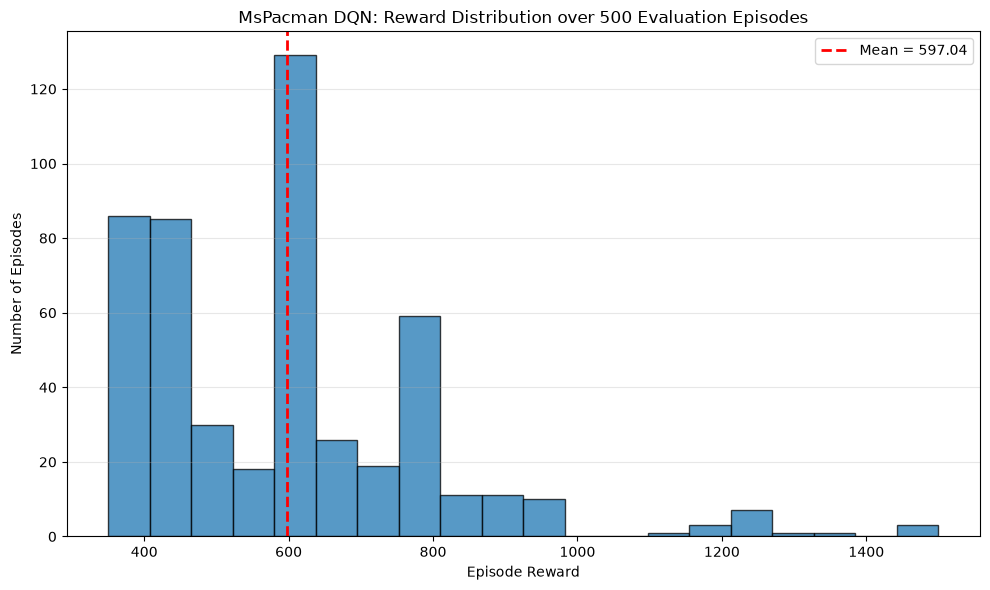

Evaluation episodes: 500
Mean reward: 597.04
Standard deviation: 199.13
Minimum reward: 350.0
Maximum reward: 1500.0


In [38]:


import numpy as np
import matplotlib.pyplot as plt

rewards = np.array(atari_eval_rewards_500)

plt.figure(figsize=(10, 6))

plt.hist(
    rewards,
    bins=20,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    rewards.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {rewards.mean():.2f}"
)

plt.xlabel("Episode Reward")
plt.ylabel("Number of Episodes")
plt.title("MsPacman DQN: Reward Distribution over 500 Evaluation Episodes")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("mspacman_eval_histogram_500.png", dpi=300)
plt.show()

print("Evaluation episodes:", len(rewards))
print("Mean reward:", round(rewards.mean(), 2))
print("Standard deviation:", round(rewards.std(), 2))
print("Minimum reward:", rewards.min())
print("Maximum reward:", rewards.max())


In [39]:

for name in [
    "atari_max_q_values",
    "atari_q_values",
    "atari_q_history",
    "atari_episode_max_q_values",
    "atari_max_q_history"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: available, length = {len(value)}")
    else:
        print(f"{name}: not found")


atari_max_q_values: not found
atari_q_values: not found
atari_q_history: not found
atari_episode_max_q_values: not found
atari_max_q_history: not found


In [40]:

for name, value in globals().copy().items():
    if ("q" in name.lower() or "history" in name.lower()) and not name.startswith("_"):
        print(name, type(value).__name__)


quit ZMQExitAutocall
deque type
DQN type
episode_max_q_values list
epsilon_history list
max_q_values list
max_q float
episode_history list
q_values ndarray
ddqn_rewards list
ddqn_max_q_values list
ddqn_losses list
ddqn_epsilons list
episode_q_values list
AtariDQN type
ATARI_TRAIN_FREQUENCY int


In [41]:

for name in [
    "episode_q_values",
    "episode_max_q_values",
    "max_q_values",
    "ddqn_max_q_values"
]:
    value = globals()[name]
    print(f"{name}:")
    print(f"  Length: {len(value)}")
    print(f"  First 5 values: {value[:5]}")
    print()


episode_q_values:
  Length: 99
  First 5 values: [20.128145217895508, 20.192991256713867, 20.243972778320312, 20.250734329223633, 20.175119400024414]

episode_max_q_values:
  Length: 2000
  First 5 values: [np.float64(0.08697062656283379), np.float64(0.05268387822434306), np.float64(0.09320517132679622), np.float64(0.08367101351420085), np.float64(0.7032424611480612)]

max_q_values:
  Length: 328
  First 5 values: [20.512453079223633, 20.51427459716797, 20.47864532470703, 20.501998901367188, 20.49532699584961]

ddqn_max_q_values:
  Length: 2500
  First 5 values: [0.24266421794891357, 0.22060899436473846, 0.15849357843399048, 1.1072828769683838, 1.5476560592651367]



In [42]:

print("MsPacman training episodes:", len(atari_episode_rewards))
print("episode_q_values:", len(episode_q_values))
print("max_q_values:", len(max_q_values))

print("\nLast 5 episode_q_values:", episode_q_values[-5:])
print("Last 5 max_q_values:", max_q_values[-5:])


MsPacman training episodes: 1000
episode_q_values: 99
max_q_values: 328

Last 5 episode_q_values: [19.712234497070312, 19.483549118041992, 19.647830963134766, 19.582990646362305, 19.744918823242188]
Last 5 max_q_values: [21.026611328125, 20.88157081604004, 20.877464294433594, 20.55810546875, 20.745702743530273]


In [43]:

import json

with open("Assignment2_DQN.ipynb", "r") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if (
        "episode_q_values.append" in source
        or "max_q_values.append" in source
    ):
        print(f"\n--- Cell {i} ---")
        for line in source.splitlines():
            if "q_values.append" in line:
                print(line.strip())



--- Cell 4 ---
max_q_values.append(max_q)
episode_max_q_values.append(

--- Cell 9 ---
q_values.append(max_q)
episode_max_q_values.append(np.mean(q_values))

--- Cell 13 ---
episode_q_values.append(q_values.max().item())
ddqn_max_q_values.append(max(episode_q_values))


In [44]:

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if "atari_episode_rewards.append" in source:
        print(f"\n--- MsPacman Training Cell {i} ---")

        for line in source.splitlines():
            if any(word in line.lower() for word in [
                "q_value",
                "max_q",
                "append",
                "torch.save"
            ]):
                print(line.strip())



--- MsPacman Training Cell 26 ---
episode_losses.append(loss)
atari_losses.append(loss)
atari_episode_rewards.append(episode_reward)

--- MsPacman Training Cell 28 ---
episode_losses.append(loss)
atari_losses.append(loss)
atari_episode_rewards.append(episode_reward)
torch.save(
torch.save(
torch.save(


In [45]:

import os

checkpoint_dir = "atari_checkpoints"

checkpoint_files = sorted(
    os.listdir(checkpoint_dir)
)

print("Available MsPacman checkpoints:\n")

for filename in checkpoint_files:
    print(filename)

print("\nTotal checkpoint files:", len(checkpoint_files))


Available MsPacman checkpoints:

mspacman_best.pth
mspacman_episode_100.pth
mspacman_episode_1000.pth
mspacman_episode_200.pth
mspacman_episode_300.pth
mspacman_episode_400.pth
mspacman_episode_500.pth
mspacman_episode_600.pth
mspacman_episode_700.pth
mspacman_episode_800.pth
mspacman_episode_900.pth
mspacman_final.pth

Total checkpoint files: 12


Episode 100: Mean Max Q-value = 0.535
Episode 200: Mean Max Q-value = 2.349
Episode 300: Mean Max Q-value = 5.003
Episode 400: Mean Max Q-value = 8.735
Episode 500: Mean Max Q-value = 11.090
Episode 600: Mean Max Q-value = 14.143
Episode 700: Mean Max Q-value = 18.832
Episode 800: Mean Max Q-value = 23.216
Episode 900: Mean Max Q-value = 25.597
Episode 1000: Mean Max Q-value = 29.930


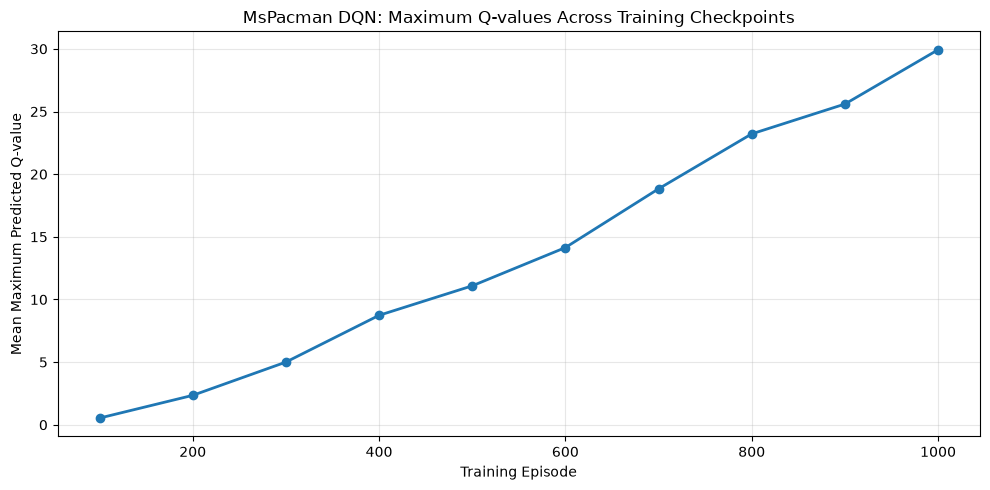

In [46]:



import numpy as np
import torch
import gymnasium as gym
import matplotlib.pyplot as plt


q_env = gym.make("ALE/MsPacman-v5", frameskip=1)

q_env = AtariPreprocessing(
    q_env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

q_env = FrameStackObservation(q_env, stack_size=4)

fixed_states = []
state, _ = q_env.reset(seed=42)

for i in range(100):
    fixed_states.append(
        np.array(state, dtype=np.uint8, copy=True)
    )

    action = q_env.action_space.sample()
    next_state, reward, terminated, truncated, info = (
        q_env.step(action)
    )

    if terminated or truncated:
        state, _ = q_env.reset(seed=42 + i + 1)
    else:
        state = next_state

q_env.close()

fixed_states = torch.from_numpy(
    np.stack(fixed_states)
).to(device)


checkpoint_episodes = list(range(100, 1001, 100))
checkpoint_max_q = []

for ep in checkpoint_episodes:
    path = f"atari_checkpoints/mspacman_episode_{ep}.pth"

    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    model = AtariDQN(num_actions).to(device)
    model.load_state_dict(checkpoint["policy_net"])
    model.eval()

    with torch.no_grad():
        q_values = model(fixed_states)
        max_q = q_values.max(dim=1).values.mean().item()

    checkpoint_max_q.append(max_q)

    print(f"Episode {ep}: Mean Max Q-value = {max_q:.3f}")


plt.figure(figsize=(10, 5))

plt.plot(
    checkpoint_episodes,
    checkpoint_max_q,
    marker="o",
    linewidth=2
)

plt.xlabel("Training Episode")
plt.ylabel("Mean Maximum Predicted Q-value")
plt.title("MsPacman DQN: Maximum Q-values Across Training Checkpoints")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("mspacman_checkpoint_max_q.png", dpi=300)
plt.show()

np.savez(
    "mspacman_checkpoint_q_values.npz",
    episodes=np.array(checkpoint_episodes),
    max_q=np.array(checkpoint_max_q)
)


In [49]:





import torch

test_model = AtariDQN(num_actions).to(device)

checkpoint = torch.load(
    "atari_checkpoints/mspacman_best.pth",
    map_location=device,
    weights_only=True
)

test_model.load_state_dict(checkpoint)
test_model.eval()

test_states = {
    "All black frames": torch.zeros(
        (1, 4, 84, 84), device=device
    ),
    "All white frames": torch.full(
        (1, 4, 84, 84), 255.0, device=device
    ),
    "Random pixel frames": torch.randint(
        0, 256, (1, 4, 84, 84), device=device
    ).float()
}

with torch.no_grad():
    for name, state in test_states.items():
        q_values = test_model(state)
        action = q_values.argmax(dim=1).item()

        valid_shape = q_values.shape == (1, num_actions)
        finite_values = torch.isfinite(q_values).all().item()
        valid_action = 0 <= action < num_actions

        passed = valid_shape and finite_values and valid_action

        print(f"{name}: {'PASS' if passed else 'FAIL'}")
        print(f"  Q-value shape: {tuple(q_values.shape)}")
        print(f"  Selected action: {action}")
        print(f"  All values finite: {finite_values}")
        print()


All black frames: PASS
  Q-value shape: (1, 9)
  Selected action: 6
  All values finite: True

All white frames: PASS
  Q-value shape: (1, 9)
  Selected action: 6
  All values finite: True

Random pixel frames: PASS
  Q-value shape: (1, 9)
  Selected action: 6
  All values finite: True



In [48]:

checkpoint = torch.load(
    "atari_checkpoints/mspacman_best.pth",
    map_location=device,
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
print("Checkpoint keys:", list(checkpoint.keys())[:20])


Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['network.0.weight', 'network.0.bias', 'network.2.weight', 'network.2.bias', 'network.4.weight', 'network.4.bias', 'network.7.weight', 'network.7.bias', 'network.9.weight', 'network.9.bias']


Action distribution:
Action 0: 95
Action 1: 98
Action 2: 72
Action 3: 17
Action 4: 17
Action 5: 0
Action 6: 81
Action 7: 33
Action 8: 87

Unique actions selected: 8


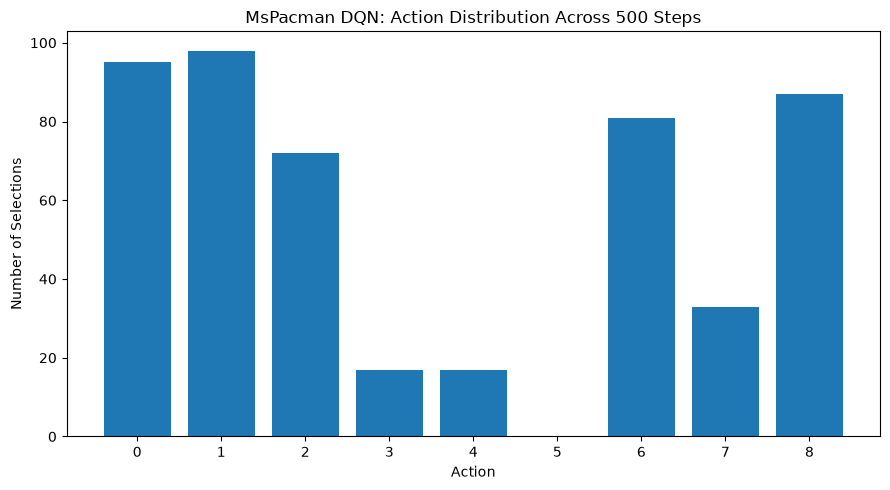

In [50]:



import numpy as np
import torch
import matplotlib.pyplot as plt
import gymnasium as gym
from collections import Counter

validation_env = gym.make("ALE/MsPacman-v5", frameskip=1)

validation_env = AtariPreprocessing(
    validation_env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)

validation_env = FrameStackObservation(
    validation_env,
    stack_size=4
)

state, _ = validation_env.reset(seed=123)

selected_actions = []

test_model.eval()

for step in range(500):
    state_tensor = torch.as_tensor(
        np.array(state),
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    with torch.no_grad():
        action = test_model(state_tensor).argmax(dim=1).item()

    selected_actions.append(action)

    state, reward, terminated, truncated, info = (
        validation_env.step(action)
    )

    if terminated or truncated:
        state, _ = validation_env.reset()

validation_env.close()

action_counts = Counter(selected_actions)

print("Action distribution:")
for action in range(num_actions):
    print(f"Action {action}: {action_counts[action]}")

print("\nUnique actions selected:", len(action_counts))


plt.figure(figsize=(9, 5))

plt.bar(
    range(num_actions),
    [action_counts[i] for i in range(num_actions)]
)

plt.xlabel("Action")
plt.ylabel("Number of Selections")
plt.title("MsPacman DQN: Action Distribution Across 500 Steps")
plt.xticks(range(num_actions))
plt.tight_layout()

plt.savefig(
    "mspacman_action_distribution.png",
    dpi=300
)

plt.show()


In [51]:



import numpy as np
import torch

validation_env = gym.make("ALE/MsPacman-v5", frameskip=1)
validation_env = AtariPreprocessing(
    validation_env,
    noop_max=30,
    frame_skip=4,
    screen_size=84,
    terminal_on_life_loss=False,
    grayscale_obs=True,
    scale_obs=False
)
validation_env = FrameStackObservation(
    validation_env, stack_size=4
)

state, _ = validation_env.reset(seed=456)
observations = []

for step in range(200):
    observations.append(np.array(state, copy=True))
    action = validation_env.action_space.sample()
    state, _, terminated, truncated, _ = validation_env.step(action)
    if terminated or truncated:
        state, _ = validation_env.reset()

validation_env.close()

states = torch.tensor(
    np.stack(observations),
    dtype=torch.float32,
    device=device
)

# Add small pixel perturbations
rng = np.random.default_rng(456)
noise = torch.tensor(
    rng.normal(0, 5, size=states.shape),
    dtype=torch.float32,
    device=device
)
perturbed_states = (states + noise).clamp(0, 255)

test_model.eval()
with torch.no_grad():
    original_q = test_model(states)
    perturbed_q = test_model(perturbed_states)

original_actions = original_q.argmax(dim=1)
perturbed_actions = perturbed_q.argmax(dim=1)

action_change_rate = (
    (original_actions != perturbed_actions)
    .float().mean().item() * 100
)

mean_q_difference = (
    (original_q - perturbed_q)
    .abs().mean().item()
)

print(f"Observations tested: {len(states)}")
print(f"Action change rate: {action_change_rate:.2f}%")
print(f"Mean absolute Q-value difference: {mean_q_difference:.4f}")


Observations tested: 200
Action change rate: 24.00%
Mean absolute Q-value difference: 0.8880


Noise std= 0 | Action change=  0.0% | Mean Q difference=0.0000
Noise std= 2 | Action change= 12.0% | Mean Q difference=0.3515
Noise std= 5 | Action change= 22.0% | Mean Q difference=0.9613
Noise std=10 | Action change= 36.0% | Mean Q difference=2.0399
Noise std=20 | Action change= 61.5% | Mean Q difference=5.5909


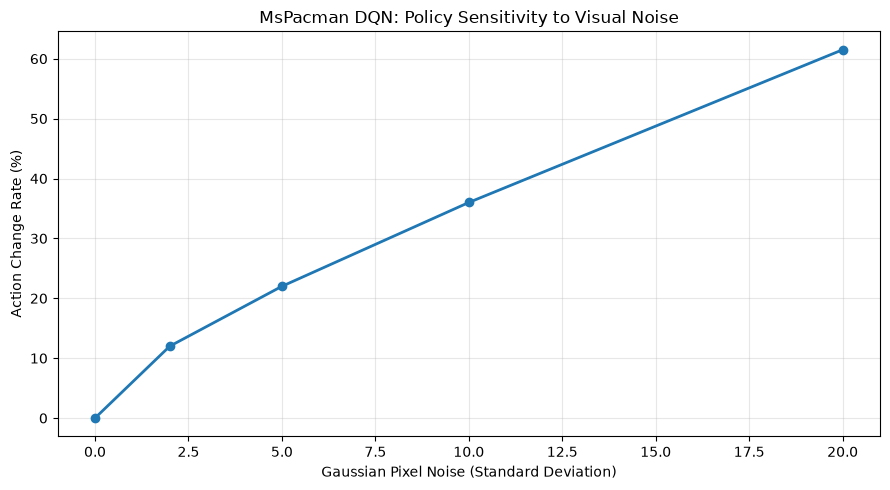

In [52]:


noise_levels = [0, 2, 5, 10, 20]
change_rates = []
q_differences = []

rng = np.random.default_rng(789)

test_model.eval()

with torch.no_grad():
    baseline_q = test_model(states)
    baseline_actions = baseline_q.argmax(dim=1)

    for sigma in noise_levels:
        noise = torch.tensor(
            rng.normal(0, sigma, size=states.shape),
            dtype=torch.float32,
            device=device
        )

        noisy_states = (states + noise).clamp(0, 255)

        noisy_q = test_model(noisy_states)
        noisy_actions = noisy_q.argmax(dim=1)

        change_rate = (
            (baseline_actions != noisy_actions)
            .float().mean().item() * 100
        )

        q_difference = (
            (baseline_q - noisy_q).abs().mean().item()
        )

        change_rates.append(change_rate)
        q_differences.append(q_difference)

        print(
            f"Noise std={sigma:2d} | "
            f"Action change={change_rate:5.1f}% | "
            f"Mean Q difference={q_difference:.4f}"
        )

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    noise_levels,
    change_rates,
    marker="o",
    linewidth=2
)

ax.set_xlabel("Gaussian Pixel Noise (Standard Deviation)")
ax.set_ylabel("Action Change Rate (%)")
ax.set_title("MsPacman DQN: Policy Sensitivity to Visual Noise")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("mspacman_noise_robustness.png", dpi=300)
plt.show()


In [53]:



import torch

gamma = 0.99

rewards = torch.tensor([10.0, 10.0], device=device)
next_q_values = torch.tensor([5.0, 5.0], device=device)

dones = torch.tensor([1.0, 0.0], device=device)

targets = rewards + gamma * next_q_values * (1 - dones)

expected_terminal = 10.0
expected_nonterminal = 10.0 + 0.99 * 5.0

assert torch.isclose(
    targets[0], torch.tensor(expected_terminal, device=device)
)

assert torch.isclose(
    targets[1], torch.tensor(expected_nonterminal, device=device)
)

print("Terminal transition target:", targets[0].item())
print("Nonterminal transition target:", targets[1].item())
print("Terminal-state target test: PASS")


Terminal transition target: 10.0
Nonterminal transition target: 14.949999809265137
Terminal-state target test: PASS


In [54]:

import inspect

print(inspect.getsource(optimize_atari_model))


def optimize_atari_model():
    if len(atari_replay_buffer) < ATARI_BATCH_SIZE:
        return None

    states, actions, rewards, next_states, dones = (
        atari_replay_buffer.sample(ATARI_BATCH_SIZE)
    )

    current_q = policy_net_atari(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)

    with torch.no_grad():
        next_q = target_net_atari(next_states).max(dim=1).values
        target_q = rewards + ATARI_GAMMA * next_q * (1 - dones)

    loss = F.smooth_l1_loss(current_q, target_q)

    atari_optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        policy_net_atari.parameters(),
        max_norm=10.0
    )

    atari_optimizer.step()

    return loss.item()



In [55]:



import torch


test_policy = AtariDQN(num_actions).to(device)
test_target = AtariDQN(num_actions).to(device)

before_sync = any(
    not torch.equal(p, t)
    for p, t in zip(
        test_policy.parameters(),
        test_target.parameters()
    )
)


test_target.load_state_dict(test_policy.state_dict())


after_sync = all(
    torch.equal(p, t)
    for p, t in zip(
        test_policy.parameters(),
        test_target.parameters()
    )
)

assert before_sync, "Networks should initially differ"
assert after_sync, "Target synchronization failed"

print("Networks initially different:", before_sync)
print("Parameters identical after synchronization:", after_sync)
print("Target network synchronization test: PASS")


Networks initially different: True
Parameters identical after synchronization: True
Target network synchronization test: PASS


In [58]:



import numpy as np
import torch

test_buffer = AtariReplayBuffer(capacity=5)

state = np.zeros((4, 84, 84), dtype=np.uint8)
next_state = np.ones((4, 84, 84), dtype=np.uint8)


assert len(test_buffer) == 0
print("Test 1 - Empty buffer: PASS")


test_buffer.push(state, 1, 1.0, next_state, False)

try:
    test_buffer.sample(2)
    raise AssertionError("Expected ValueError was not raised")
except ValueError:
    print("Test 2 - Insufficient samples: PASS")


for i in range(10):
    test_buffer.push(state, i % 9, float(i), next_state, False)

assert len(test_buffer) == 5
stored_rewards = [transition[2] for transition in test_buffer.buffer]
assert stored_rewards == [5.0, 6.0, 7.0, 8.0, 9.0]
print("Test 3 - Capacity overflow: PASS")


batch = test_buffer.sample(3)
states, actions, rewards, next_states, dones = batch

assert states.shape == (3, 4, 84, 84)
assert next_states.shape == (3, 4, 84, 84)
assert actions.shape == (3,)
assert rewards.shape == (3,)
assert dones.shape == (3,)

assert states.dtype == torch.uint8
assert actions.dtype == torch.long
assert rewards.dtype == torch.float32
assert dones.dtype == torch.float32

print("Test 4 - Data types and tensor shapes: PASS")

copy_buffer = AtariReplayBuffer(capacity=2)

original_state = np.zeros((4, 84, 84), dtype=np.uint8)
copy_buffer.push(
    original_state, 0, 1.0, original_state, False
)

original_state[:] = 255

stored_state = copy_buffer.buffer[0][0]
assert np.all(stored_state == 0)

print("Test 5 - State-copy independence: PASS")

print("\nAll 5 replay buffer tests passed!")



Test 1 - Empty buffer: PASS
Test 2 - Insufficient samples: PASS
Test 3 - Capacity overflow: PASS
Test 4 - Data types and tensor shapes: PASS
Test 5 - State-copy independence: PASS

All 5 replay buffer tests passed!


In [57]:

import json

with open("Assignment2_DQN.ipynb", "r") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if "class AtariReplayBuffer" in source:
        print(f"--- Cell {i}: AtariReplayBuffer ---")
        print(source)


--- Cell 23: AtariReplayBuffer ---

import random
from collections import deque
import numpy as np
import torch

class AtariReplayBuffer:
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((
            np.array(state, dtype=np.uint8, copy=True),
            int(action),
            float(reward),
            np.array(next_state, dtype=np.uint8, copy=True),
            bool(done)
        ))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            torch.from_numpy(np.stack(states)).to(device),
            torch.tensor(actions, dtype=torch.long, device=device),
            torch.tensor(rewards, dtype=torch.float32, device=device),
            torch.from_numpy(np.stack(next_states)).to(device),
            torch.tensor(dones, dtype=torch.fl

In [59]:

import os

print("=== Saved Figures ===")
figures = sorted([
    f for f in os.listdir(".")
    if f.endswith((".png", ".jpg", ".jpeg", ".pdf"))
])

for f in figures:
    print(f)

print("\n=== Saved NumPy Results ===")
results = sorted([
    f for f in os.listdir(".")
    if f.endswith((".npy", ".npz"))
])

for f in results:
    print(f)

print("\n=== MsPacman Checkpoints ===")
for f in sorted(os.listdir("atari_checkpoints")):
    print(f)


=== Saved Figures ===
cartpole_ddqn_best_histogram.png
cartpole_evaluation_histogram.png
cartpole_improved_evaluation_histogram.png
cartpole_max_q_values.png
cartpole_training_curve.png
mspacman_action_distribution.png
mspacman_checkpoint_max_q.png
mspacman_eval_histogram.png
mspacman_eval_histogram_500.png
mspacman_noise_robustness.png
mspacman_training_rewards.png

=== Saved NumPy Results ===
atari_episode_rewards.npy
cartpole_ddqn_best_eval_rewards.npy
cartpole_ddqn_training_stats.npz
cartpole_eval_rewards.npy
cartpole_improved_eval_rewards.npy
cartpole_improved_training_stats.npz
cartpole_training_stats.npz
mspacman_best_eval_rewards.npy
mspacman_checkpoint_q_values.npz
mspacman_eval_rewards_500.npy

=== MsPacman Checkpoints ===
mspacman_best.pth
mspacman_episode_100.pth
mspacman_episode_1000.pth
mspacman_episode_200.pth
mspacman_episode_300.pth
mspacman_episode_400.pth
mspacman_episode_500.pth
mspacman_episode_600.pth
mspacman_episode_700.pth
mspacman_episode_800.pth
mspacman_epis

In [60]:

import numpy as np

files = [
    "cartpole_training_stats.npz",
    "cartpole_improved_training_stats.npz",
    "cartpole_ddqn_training_stats.npz"
]

for filename in files:
    print(f"\n=== {filename} ===")

    with np.load(filename) as data:
        for key in data.files:
            values = data[key]
            print(
                f"{key}: shape={values.shape}, "
                f"dtype={values.dtype}"
            )



=== cartpole_training_stats.npz ===
rewards: shape=(1000,), dtype=float64
max_q_values: shape=(1000,), dtype=float64
losses: shape=(1000,), dtype=float64
epsilons: shape=(1000,), dtype=float64

=== cartpole_improved_training_stats.npz ===
rewards: shape=(2000,), dtype=float64
max_q_values: shape=(2000,), dtype=float64
losses: shape=(2000,), dtype=float64
episodes: shape=(2000,), dtype=int64

=== cartpole_ddqn_training_stats.npz ===
rewards: shape=(2500,), dtype=float64
max_q_values: shape=(2500,), dtype=float64
losses: shape=(2500,), dtype=float64
epsilons: shape=(2500,), dtype=float64


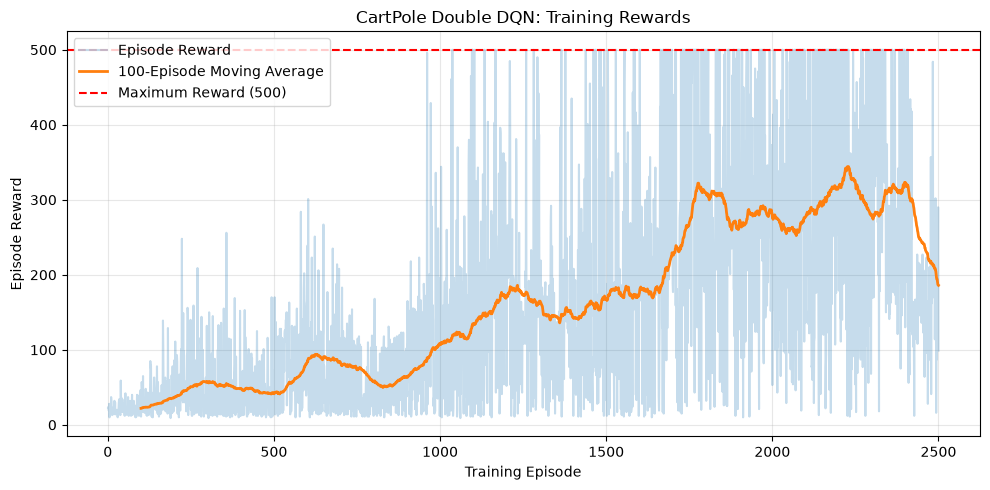

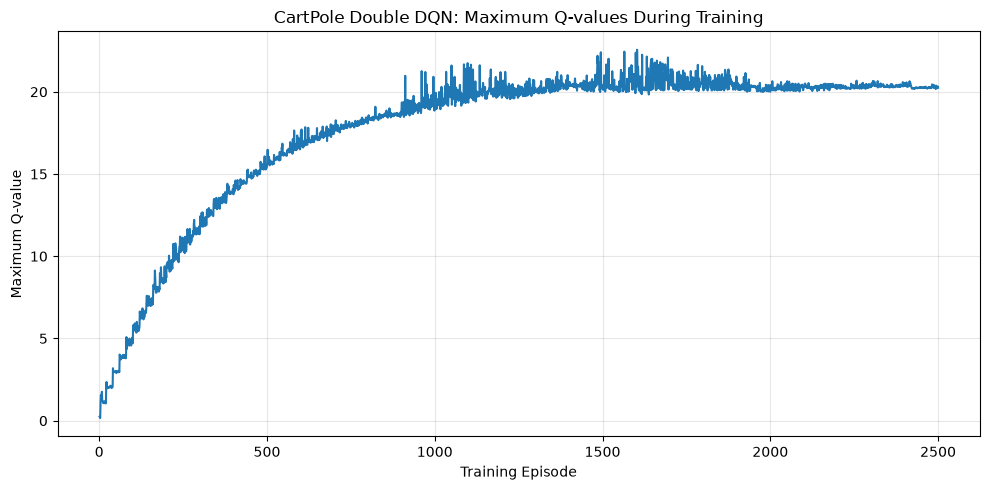

Final 100-episode average reward: 185.93
Maximum training reward: 500.0
Saved both Double DQN plots successfully!


In [61]:

import numpy as np
import matplotlib.pyplot as plt


data = np.load("cartpole_ddqn_training_stats.npz")

rewards = data["rewards"]
max_q = data["max_q_values"]
episodes = np.arange(1, len(rewards) + 1)


window = 100
moving_avg = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)


plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    rewards,
    alpha=0.25,
    label="Episode Reward"
)

plt.plot(
    episodes[window - 1:],
    moving_avg,
    linewidth=2,
    label="100-Episode Moving Average"
)

plt.axhline(
    y=500,
    color="red",
    linestyle="--",
    label="Maximum Reward (500)"
)

plt.xlabel("Training Episode")
plt.ylabel("Episode Reward")
plt.title("CartPole Double DQN: Training Rewards")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cartpole_ddqn_training_rewards.png",
    dpi=300
)

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    max_q,
    linewidth=1.5
)

plt.xlabel("Training Episode")
plt.ylabel("Maximum Q-value")
plt.title("CartPole Double DQN: Maximum Q-values During Training")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cartpole_ddqn_max_q_values.png",
    dpi=300
)

plt.show()

print("Final 100-episode average reward:", round(rewards[-100:].mean(), 2))
print("Maximum training reward:", rewards.max())
print("Saved both Double DQN plots successfully!")
